# 3D Helmholtz PFDM — numerics-informed hyperparameter experiment

We consider

\[
(-\Delta+\kappa^2)u=f
\qquad \text{on }(0,1)^3,
\]

with homogeneous Dirichlet boundary conditions and manufactured exact solution

\[
u^\star(x,y,z)=\sin(\pi x)\sin(\pi y)\sin(\pi z).
\]

The proposed hyperparameter rule is

\[
\tau=p=2,\qquad
C=\widehat C_{\rm defect},\qquad
\sigma_f=\|u_h\|_\infty,
\]

while the Matérn-\(3/2\) length scale is chosen from the adjacent-grid prior correlation

\[
\rho(h)\in\{0.3,0.5,0.7,0.8\}.
\]

We repeat the experiment for

\[
N_x\in\{4,5,6,8\},
\qquad h=\frac{1}{N_x+1}.
\]

For each \((h,\rho)\), we report \(\widehat C\), oracle \(C\) (diagnostic only), posterior mean error, 95% coverage, and average CI half-width.


In [13]:
using LinearAlgebra
using SparseArrays
using Statistics
using SpecialFunctions
using Printf
using Plots

println("Packages loaded.")


Packages loaded.


In [14]:
# ============================================================
# Problem and Matérn-3/2 kernel
# ============================================================

ν_fixed = 1.5
p_order = 2
τ_fixed = 2
k_wave  = 1.0
jitter  = 1e-10

u_exact(x, y, z, k) =
    sin(π*x) * sin(π*y) * sin(π*z)

f_func(x, y, z, k) =
    (3π^2 + k^2) * sin(π*x) * sin(π*y) * sin(π*z)

function matern_kernel_3d(x1, x2; ν=1.5, ℓ=1.0, σf=1.0)
    r = sqrt(sum((x1 .- x2).^2))
    r == 0 && return σf^2
    z = sqrt(2ν) * r / ℓ

    if ν == 0.5
        return σf^2 * exp(-z)
    elseif ν == 1.5
        return σf^2 * (1 + z) * exp(-z)
    elseif ν == 2.5
        return σf^2 * (1 + z + z^2/3) * exp(-z)
    else
        return σf^2 * (2^(1-ν)/gamma(ν)) * z^ν * besselk(ν, z)
    end
end

function kernel_matrix_3d(X1, X2; ν=1.5, ℓ=1.0, σf=1.0)
    n1, n2 = length(X1), length(X2)
    K = zeros(n1, n2)
    for i in 1:n1, j in 1:n2
        K[i,j] = matern_kernel_3d(
            X1[i], X2[j];
            ν=ν, ℓ=ℓ, σf=σf
        )
    end
    return K
end


kernel_matrix_3d (generic function with 1 method)

In [15]:
# ============================================================
# 3D Helmholtz finite-difference operator
# D_h = -Delta_h + k^2 I
# ============================================================

function build_Dh_3d_helmholtz(Nx, Ny, Nz, h, k)
    N = Nx * Ny * Nz
    index(i,j,l) = i + (j-1)*Nx + (l-1)*Nx*Ny

    rows = Int[]
    cols = Int[]
    vals = Float64[]

    for l in 1:Nz, j in 1:Ny, i in 1:Nx
        q = index(i,j,l)

        push!(rows,q)
        push!(cols,q)
        push!(vals, 6.0/h^2 + k^2)

        if i > 1
            push!(rows,q); push!(cols,index(i-1,j,l)); push!(vals,-1.0/h^2)
        end
        if i < Nx
            push!(rows,q); push!(cols,index(i+1,j,l)); push!(vals,-1.0/h^2)
        end
        if j > 1
            push!(rows,q); push!(cols,index(i,j-1,l)); push!(vals,-1.0/h^2)
        end
        if j < Ny
            push!(rows,q); push!(cols,index(i,j+1,l)); push!(vals,-1.0/h^2)
        end
        if l > 1
            push!(rows,q); push!(cols,index(i,j,l-1)); push!(vals,-1.0/h^2)
        end
        if l < Nz
            push!(rows,q); push!(cols,index(i,j,l+1)); push!(vals,-1.0/h^2)
        end
    end

    return sparse(rows, cols, vals, N, N)
end

function make_grid_3d(Nx)
    h = 1.0 / (Nx + 1)
    xs = collect(range(h, step=h, length=Nx))
    ys = collect(range(h, step=h, length=Nx))
    zs = collect(range(h, step=h, length=Nx))

    X = [[x,y,z] for z in zs for y in ys for x in xs]

    return h, xs, ys, zs, X
end

function solve_fdm_helmholtz(Nx; k=k_wave)
    h, xs, ys, zs, X = make_grid_3d(Nx)

    Dh = build_Dh_3d_helmholtz(
        Nx, Nx, Nx, h, k
    )

    b = [
        f_func(x,y,z,k)
        for z in zs, y in ys, x in xs
    ] |> vec

    u_fdm = Dh \ b

    return h, xs, ys, zs, X, Dh, b, u_fdm
end


solve_fdm_helmholtz (generic function with 1 method)

In [16]:
# ============================================================
# Coarsening-based C calibration in 3D
#
# D_h u - f = c(x) h^p + higher-order terms
#
# For u_h, evaluate the 2h Helmholtz stencil:
#
#   defect = D_{2h} u_h - f
#
# then
#
#   c_hat = defect / ((2^p - 1) h^p)
#   C_hat = mean(c_hat.^2)
#
# The reaction term k^2 u is evaluated pointwise and therefore
# contributes no additional discretisation error.
# ============================================================

function estimate_C_coarsening_3d(u_h, h, Nx; p=2, k=k_wave)

    U = reshape(u_h, Nx, Nx, Nx)
    h2 = 2.0*h

    centers = 2:(Nx-1)
    isempty(centers) &&
        error("Nx must be at least 3.")

    function uval(i,j,l)
        if i == 0 || i == Nx+1 ||
           j == 0 || j == Nx+1 ||
           l == 0 || l == Nx+1
            return 0.0
        elseif 1 <= i <= Nx &&
               1 <= j <= Nx &&
               1 <= l <= Nx
            return U[i,j,l]
        else
            error("2h stencil left physical domain")
        end
    end

    defect = Float64[]
    c_hat  = Float64[]

    for l in centers, j in centers, i in centers
        x = i*h
        y = j*h
        z = l*h

        D2h_u = (
            6uval(i,j,l)
            - uval(i-2,j,l) - uval(i+2,j,l)
            - uval(i,j-2,l) - uval(i,j+2,l)
            - uval(i,j,l-2) - uval(i,j,l+2)
        ) / h2^2 + k^2*uval(i,j,l)

        d = D2h_u - f_func(x,y,z,k)
        c = d / ((2.0^p - 1.0) * h^p)

        push!(defect, d)
        push!(c_hat, c)
    end

    C_hat = mean(c_hat.^2)

    return C_hat, c_hat, defect
end

# Oracle C on the SAME centers as the coarsening estimator.
# Diagnostic only; never used by the method.
function oracle_C_3d(h, Nx; p=2, k=k_wave)

    centers = 2:(Nx-1)
    vals = Float64[]

    function ustar(i,j,l)
        if i == 0 || i == Nx+1 ||
           j == 0 || j == Nx+1 ||
           l == 0 || l == Nx+1
            return 0.0
        end
        return u_exact(i*h, j*h, l*h, k)
    end

    for l in centers, j in centers, i in centers
        x = i*h
        y = j*h
        z = l*h

        Dh_u = (
            6ustar(i,j,l)
            - ustar(i-1,j,l) - ustar(i+1,j,l)
            - ustar(i,j-1,l) - ustar(i,j+1,l)
            - ustar(i,j,l-1) - ustar(i,j,l+1)
        ) / h^2 + k^2*ustar(i,j,l)

        e = Dh_u - f_func(x,y,z,k)
        push!(vals, e / h^p)
    end

    return mean(vals.^2)
end


oracle_C_3d (generic function with 1 method)

In [17]:
# ============================================================
# Matérn-3/2: adjacent-grid correlation rho(h) -> ell
#
# rho(h) = (1+z)exp(-z), z=sqrt(3)h/ell
# ============================================================

function ell_from_rho_matern32(h, rho; tol=1e-12, maxiter=200)
    @assert 0.0 < rho < 1.0

    fz(z) = (1.0 + z) * exp(-z) - rho

    lo = 0.0
    hi = 1.0

    while fz(hi) > 0.0
        hi *= 2.0
    end

    for _ in 1:maxiter
        mid = 0.5*(lo + hi)

        if fz(mid) > 0.0
            lo = mid
        else
            hi = mid
        end

        if hi - lo < tol
            break
        end
    end

    z = 0.5*(lo + hi)
    return sqrt(3.0)*h/z
end

for rho in [0.3,0.5,0.7,0.8]
    @printf(
        "rho=%.1f -> ell/h=%.4f\n",
        rho,
        ell_from_rho_matern32(1.0,rho)
    )
end


rho=0.3 -> ell/h=0.7101
rho=0.5 -> ell/h=1.0320
rho=0.7 -> ell/h=1.5784
rho=0.8 -> ell/h=2.1010


In [23]:
# ============================================================
# PFDM posterior at the grid points
# ============================================================

function run_pfdm_helmholtz(
    Nx;
    rho_adj,
    C,
    σf,
    ν=ν_fixed,
    τ=τ_fixed,
    k=k_wave
)
    h, xs, ys, zs, X, Dh, b, u_fdm =
        solve_fdm_helmholtz(Nx; k=k)

    N = Nx^3
    ell = ell_from_rho_matern32(h, rho_adj)

    K = kernel_matrix_3d(
        X, X;
        ν=ν,
        ℓ=ell,
        σf=σf
    )

    noise_var = C * h^(2τ)

    A = Hermitian(
        Dh*K*Dh' +
        noise_var*I +
        jitter*I
    )

    chol = cholesky(A)
    alpha = chol \ b

    mu = K * (Dh' * alpha)

    # Posterior covariance at the grid points
    B = Dh * K
    V = chol.L \ B
    Sigma_post = K - V' * V

    std_post = sqrt.(
        max.(diag(Sigma_post), 0.0)
    )

    u_true = [
        u_exact(x,y,z,k)
        for z in zs, y in ys, x in xs
    ] |> vec

    return (
        h=h,
        xs=xs,
        ys=ys,
        zs=zs,
        X=X,
        u_fdm=u_fdm,
        u_true=u_true,
        mu=mu,
        std=std_post,
        ell=ell
    )
end

function posterior_metrics(mu, std, u_true)
    err = mu .- u_true

    rmse = sqrt(mean(err.^2))
    linf = maximum(abs.(err))

    lower = mu .- 1.96 .* std
    upper = mu .+ 1.96 .* std

    coverage = mean(
        (u_true .>= lower) .&
        (u_true .<= upper)
    )

    mean_halfwidth = mean(1.96 .* std)

    return rmse, linf, coverage, mean_halfwidth
end


posterior_metrics (generic function with 1 method)

In [28]:
# ============================================================
# Length-scale sensitivity experiment
#
# C and sigma_f are fixed by numerics-informed calibration.
# Only ell is varied directly on ell_grid.
# ============================================================

Nx_list = [4, 5, 6, 8]

# Direct grid for ell
ell_grid = [0.01, 0.03, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0]

results_ell = NamedTuple[]

println("=== 3D Helmholtz: length-scale sensitivity ===")
println("tau = p = 2")
println("sigma_f = ||u_h||_inf")
println("C = coarsening-defect estimator")
println("ell is varied directly over ell_grid")
println()

for nx in Nx_list

    h, xs, ys, zs, X, Dh, b, u_fdm =
        solve_fdm_helmholtz(nx)

    # --------------------------------------------------------
    # Numerics-informed sigma and C
    # --------------------------------------------------------
    sigma_rms  = sqrt(mean(u_fdm.^2))
    sigma_max  = maximum(abs.(u_fdm))
    sigma_used = sigma_max

    C_hat, c_hat, defect =
        estimate_C_coarsening_3d(
            u_fdm, h, nx;
            p=p_order
        )

    C_oracle =
        oracle_C_3d(
            h, nx;
            p=p_order
        )

    # --------------------------------------------------------
    # Exact solution on the FDM grid
    # --------------------------------------------------------
    u_true_grid = [
        u_exact(x,y,z,k_wave)
        for z in zs, y in ys, x in xs
    ] |> vec

    fdm_linf =
        maximum(abs.(u_fdm - u_true_grid))

    println("-------------------------------------------")
    @printf("Nx = %d, h = %.6g\n", nx, h)
    @printf("sigma_rms = %.6g\n", sigma_rms)
    @printf("sigma_max = %.6g\n", sigma_max)
    @printf("C_hat     = %.6g\n", C_hat)
    @printf("C_oracle  = %.6g\n", C_oracle)
    @printf("C ratio   = %.6g\n", C_hat / C_oracle)
    @printf("RMS(c_hat)= %.6g\n", sqrt(mean(c_hat.^2)))
    @printf("FDM Linf  = %.6g\n", fdm_linf)

    println("")

    # --------------------------------------------------------
    # Sweep ell directly
    # --------------------------------------------------------
    for ell in ell_grid

        # ----------------------------------------------------
        # Prior
        # ----------------------------------------------------
        K = kernel_matrix_3d(
            X, X;
            ν=ν_fixed,
            ℓ=ell,
            σf=sigma_used
        )

        noise_var =
            C_hat * h^(2τ_fixed)

        A = Hermitian(
            Dh * K * Dh' +
            noise_var * I +
            jitter * I
        )

        chol = cholesky(A)

        alpha = chol \ b

        # ----------------------------------------------------
        # Posterior on the FDM grid
        # ----------------------------------------------------
        mu =
            K * (Dh' * alpha)

        B =
            Dh * K

        V =
            chol.L \ B

        Sigma_post =
            K - V' * V

        std_post =
            sqrt.(
                max.(
                    diag(Sigma_post),
                    0.0
                )
            )

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------
        rmse, linf, coverage, mean_hw =
            posterior_metrics(
                mu,
                std_post,
                u_true_grid
            )

        push!(
            results_ell,
            (
                Nx=nx,
                h=h,

                ell=ell,
                ell_over_h=ell/h,

                sigma_rms=sigma_rms,
                sigma_max=sigma_max,
                sigma_used=sigma_used,

                C_hat=C_hat,
                C_oracle=C_oracle,
                C_ratio=C_hat/C_oracle,

                fdm_linf=fdm_linf,

                post_rmse=rmse,
                post_linf=linf,

                coverage=coverage,
                mean_CI_halfwidth=mean_hw,

                max_std=maximum(std_post)
            )
        )

        @printf(
            "ell=%7.3g  ell/h=%7.3f  RMSE=%9.5g  Linf=%9.5g  coverage=%6.3f  CIhalf=%9.5g  maxstd=%9.5g\n",
            ell,
            ell/h,
            rmse,
            linf,
            coverage,
            mean_hw,
            maximum(std_post)
        )
    end
end

=== 3D Helmholtz: length-scale sensitivity ===
tau = p = 2
sigma_f = ||u_h||_inf
C = coarsening-defect estimator
ell is varied directly over ell_grid

-------------------------------------------
Nx = 4, h = 0.2
sigma_rms = 0.510128
sigma_max = 0.888133
C_hat     = 409.916
C_oracle  = 427.457
C ratio   = 0.958965
RMS(c_hat)= 20.2464
FDM Linf  = 0.0278945

ell=   0.01  ell/h=  0.050  RMSE=  0.01554  Linf= 0.027055  coverage= 0.500  CIhalf= 0.014505  maxstd=0.0088159
ell=   0.03  ell/h=  0.150  RMSE=  0.01554  Linf= 0.027056  coverage= 0.500  CIhalf= 0.014505  maxstd=0.0088159
ell=   0.05  ell/h=  0.250  RMSE=  0.01556  Linf=  0.02709  coverage= 0.500  CIhalf= 0.014505  maxstd=0.0088159
ell=    0.1  ell/h=  0.500  RMSE=   0.0158  Linf= 0.027506  coverage= 0.500  CIhalf= 0.014506  maxstd= 0.008817
ell=    0.2  ell/h=  1.000  RMSE= 0.015965  Linf= 0.027789  coverage= 0.500  CIhalf= 0.014506  maxstd=0.0088176
ell=    0.5  ell/h=  2.500  RMSE=  0.01597  Linf= 0.027772  coverage= 0.500  CIhalf

In [29]:
# ============================================================
# Compact results table
# ============================================================

println("\n=== Compact results table ===")

@printf(
    "%-4s %-8s %-5s %-8s %-12s %-12s %-10s %-10s %-10s\n",
    "Nx","h","rho","ell/h",
    "C_hat","C_oracle",
    "RMSE","Linf","coverage"
)

for r in results
    @printf(
        "%-4d %-8.4f %-5.2f %-8.3f %-12.4g %-12.4g %-10.4g %-10.4g %-10.3f\n",
        r.Nx,
        r.h,
        r.rho,
        r.ell_over_h,
        r.C_hat,
        r.C_oracle,
        r.post_rmse,
        r.post_linf,
        r.coverage
    )
end



=== Compact results table ===
Nx   h        rho   ell/h    C_hat        C_oracle     RMSE       Linf       coverage  
4    0.2000   0.30  0.710    409.9        427.5        0.01591    0.0277     0.500     
4    0.2000   0.50  1.032    409.9        427.5        0.01597    0.02779    0.500     
4    0.2000   0.70  1.578    409.9        427.5        0.01598    0.02782    0.500     
4    0.2000   0.80  2.101    409.9        427.5        0.01598    0.0278     0.500     
5    0.1667   0.30  0.710    327.3        337          0.01038    0.02233    0.352     
5    0.1667   0.50  1.032    327.3        337          0.01039    0.02236    0.352     
5    0.1667   0.70  1.578    327.3        337          0.0104     0.02237    0.352     
5    0.1667   0.80  2.101    327.3        337          0.0104     0.02237    0.352     
6    0.1429   0.30  0.710    272.7        278.6        0.007292   0.01517    0.148     
6    0.1429   0.50  1.032    272.7        278.6        0.007298   0.01518    0.148     
6

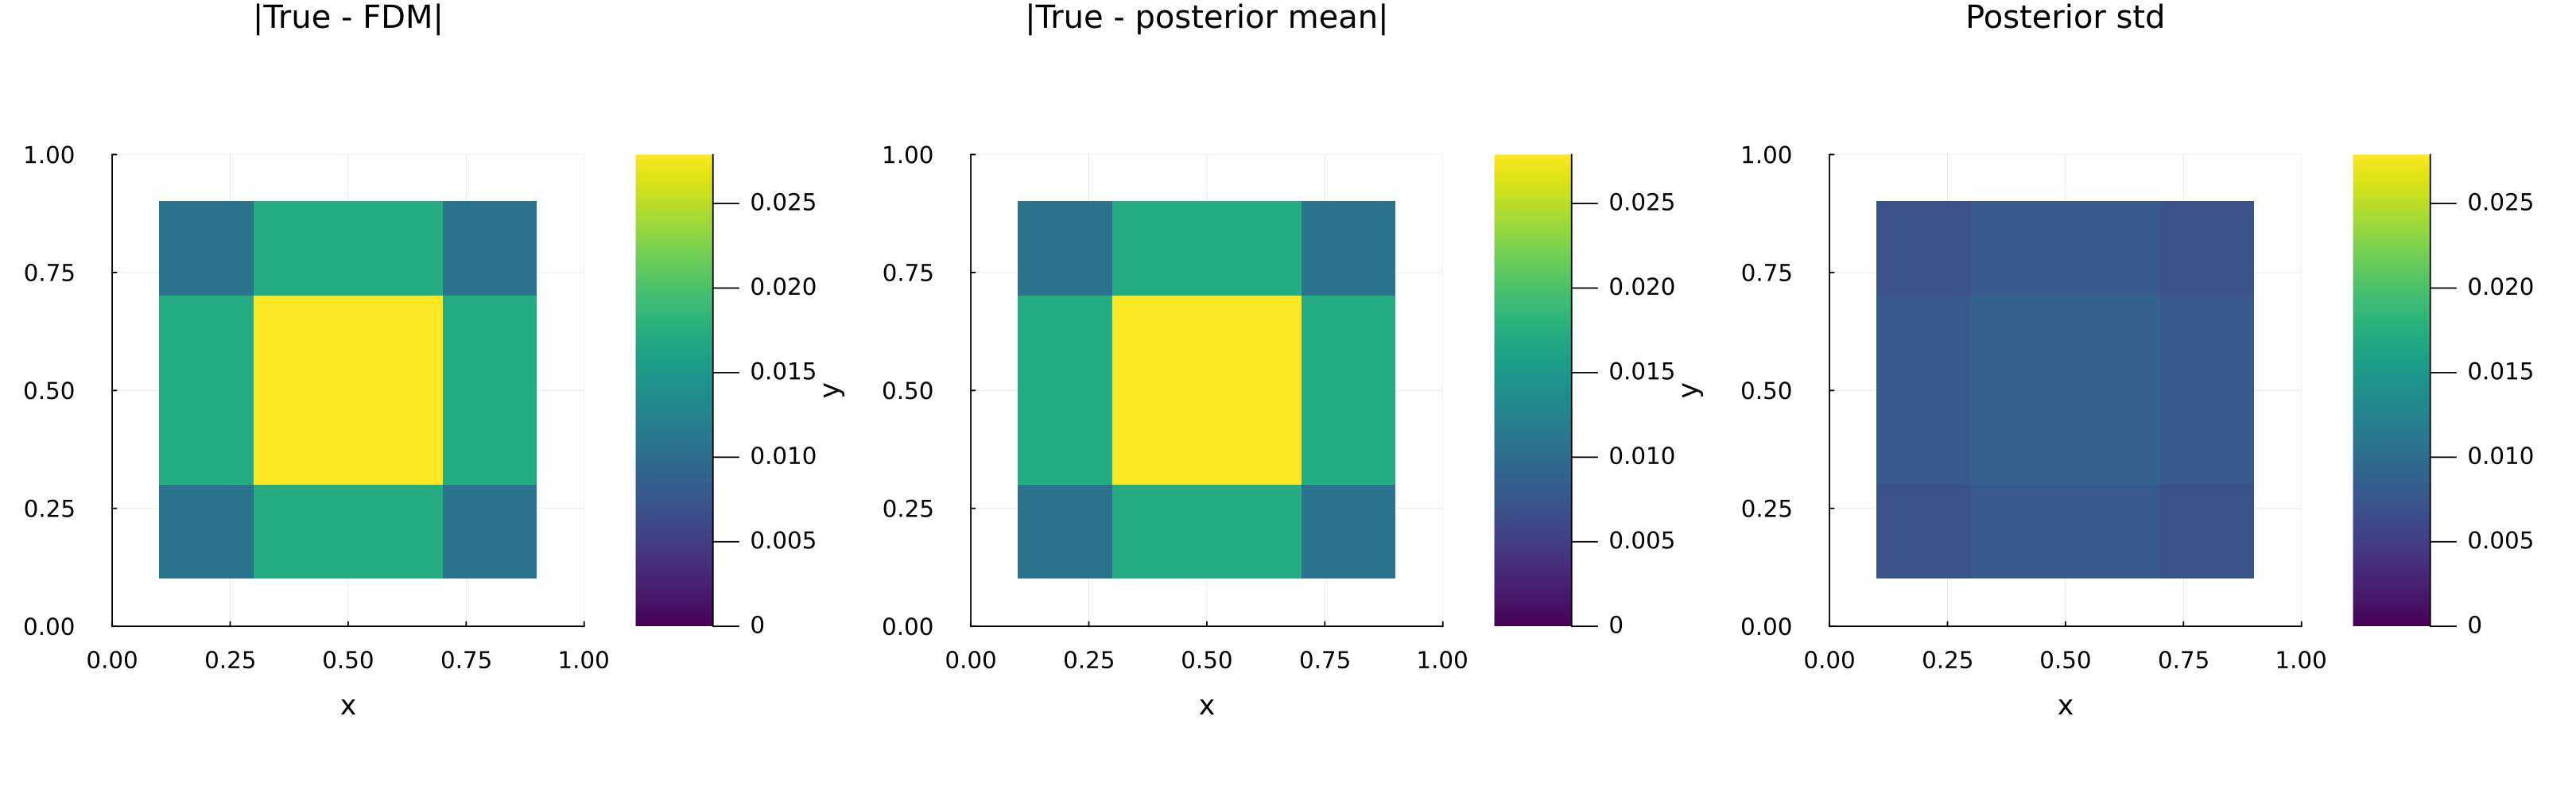

Saved helmholtz3d_Nx4_zmid_rho0p5_common_scale.png | Nx=4 h=0.2 z=0.4000 C=409.92
max |True-FDM|  = 0.0278945
max |True-Post| = 0.027793
max posterior std = 0.0088176
Saved helmholtz3d_Nx5_zmid_rho0p5_common_scale.png | Nx=5 h=0.16667 z=0.5000 C=327.33
max |True-FDM|  = 0.0223892
max |True-Post| = 0.0223635
max posterior std = 0.00429945
Saved helmholtz3d_Nx6_zmid_rho0p5_common_scale.png | Nx=6 h=0.14286 z=0.5714 C=272.73
max |True-FDM|  = 0.0151901
max |True-Post| = 0.0151795
max posterior std = 0.00224531
Saved helmholtz3d_Nx8_zmid_rho0p5_common_scale.png | Nx=8 h=0.11111 z=0.4444 C=208.73
max |True-FDM|  = 0.00943557
max |True-Post| = 0.0094332
max posterior std = 0.000816384


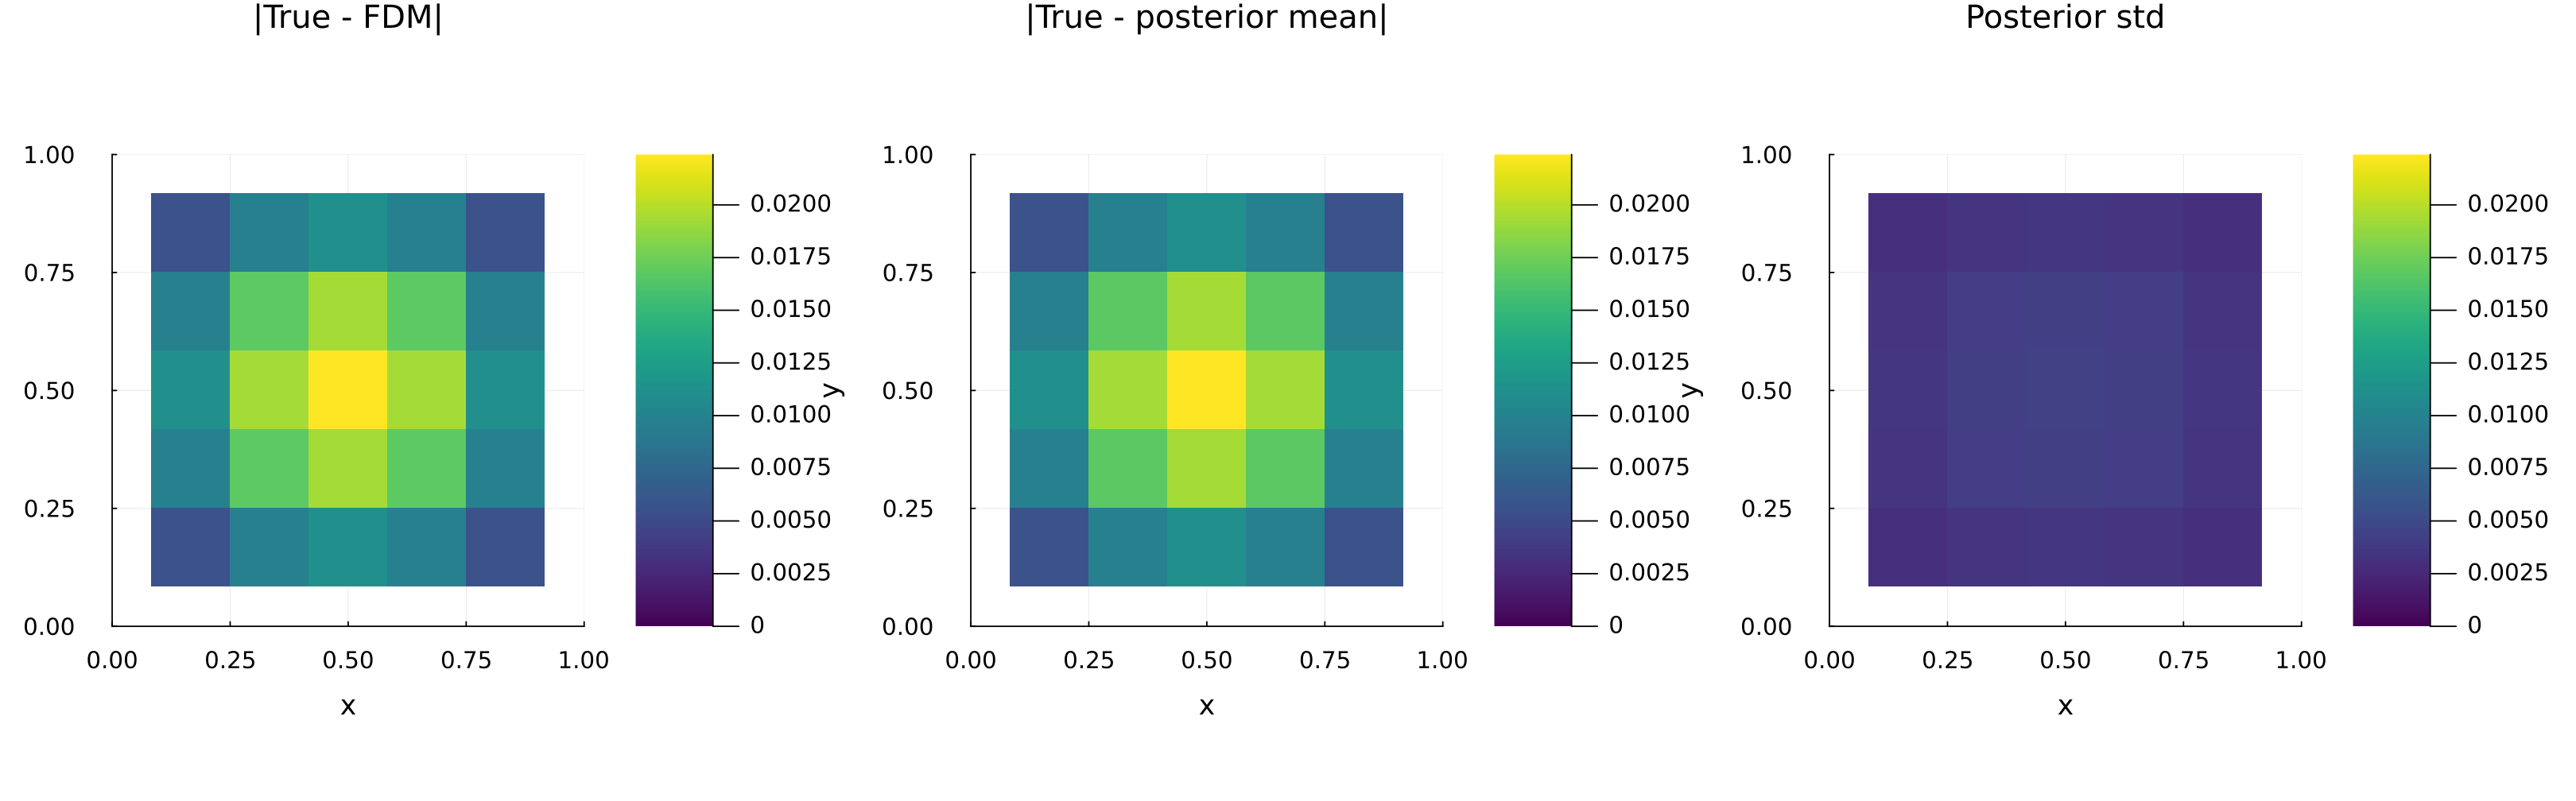

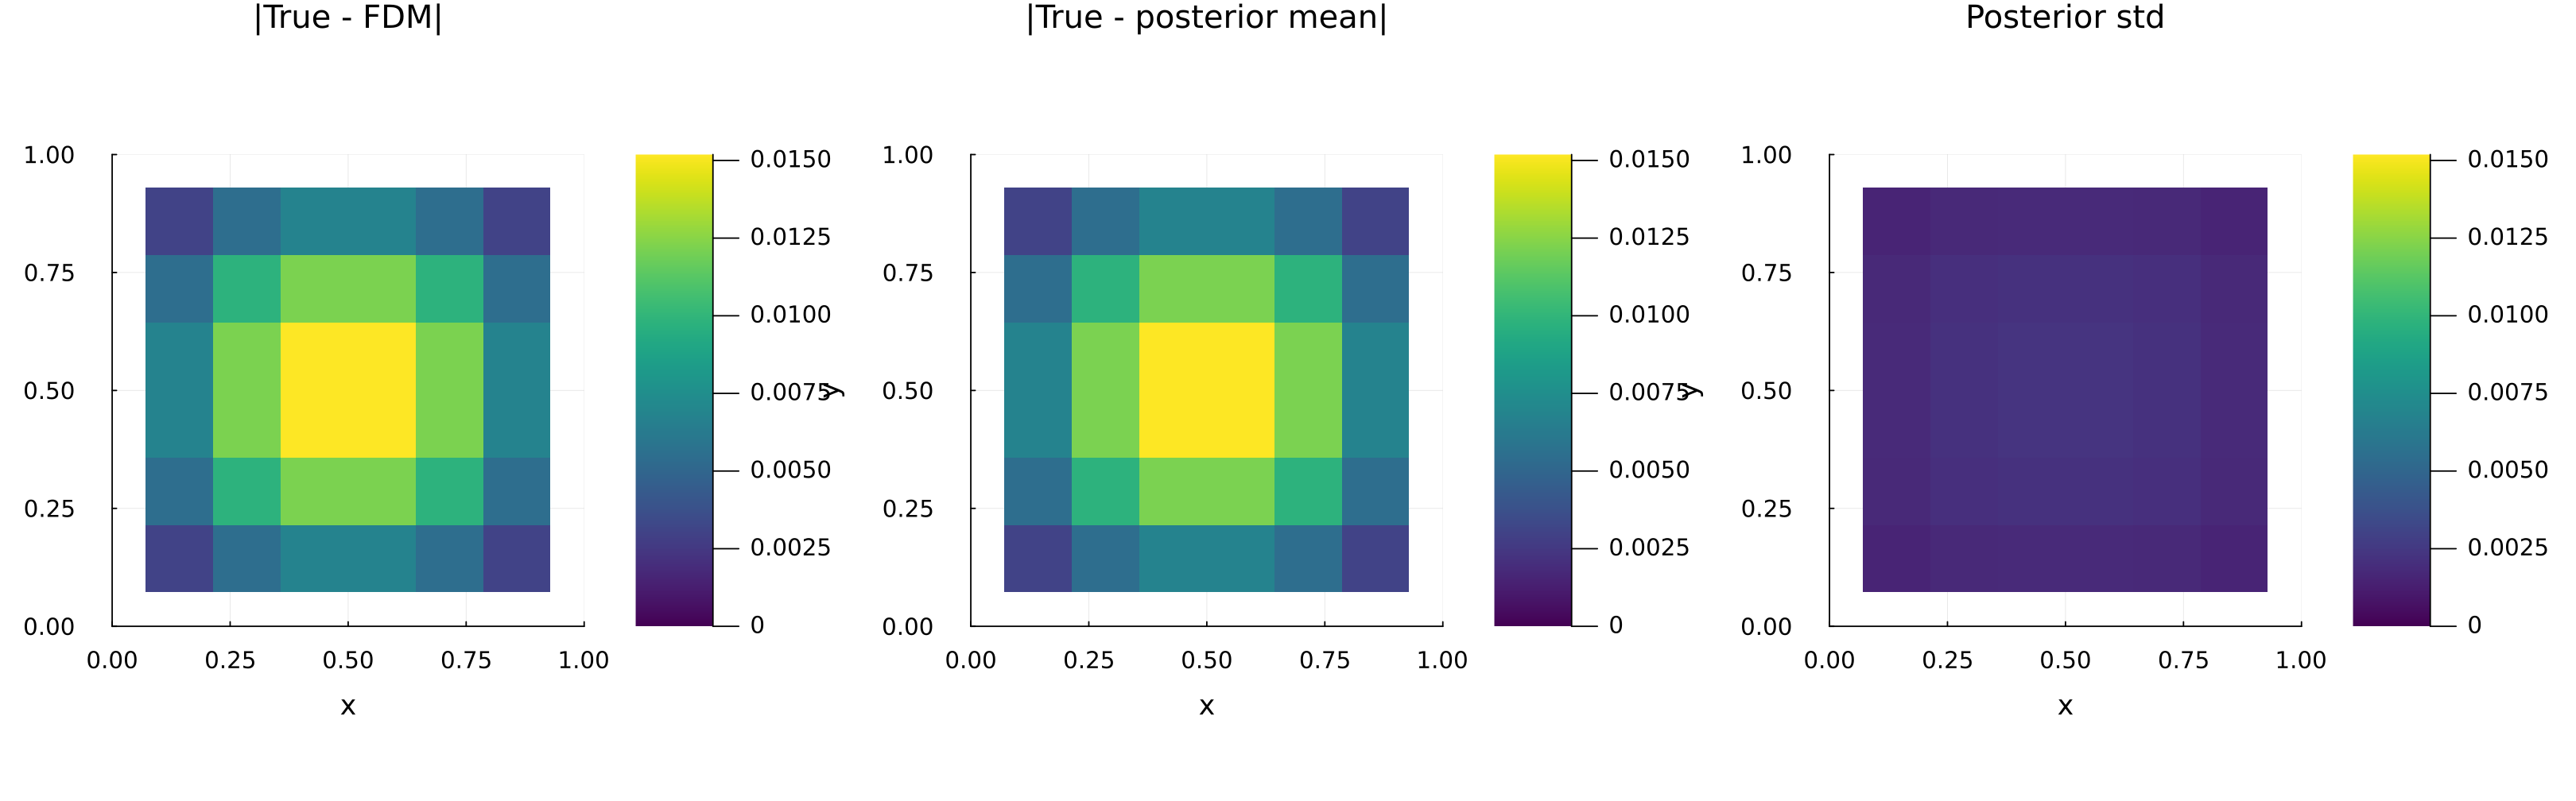

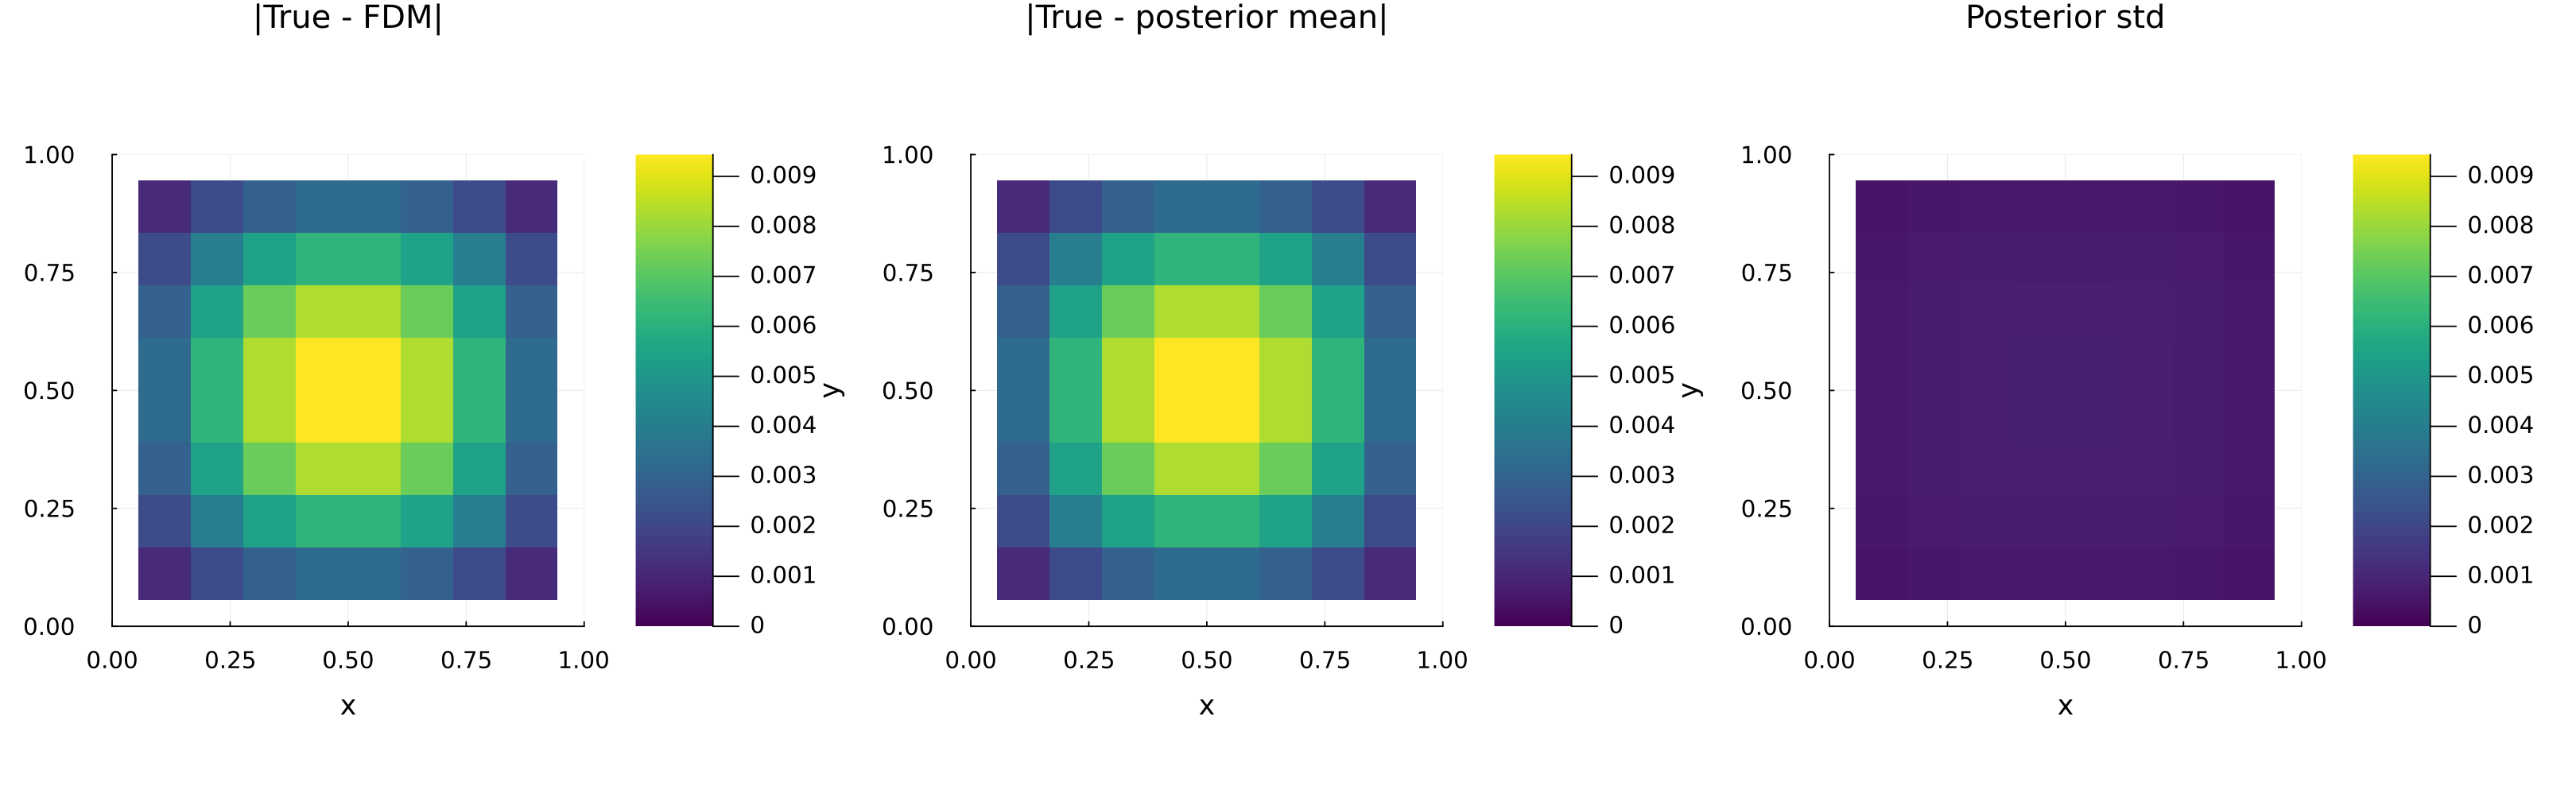

In [30]:
# ============================================================
# Paper-style figures for rho = 0.5
#
# For each Nx, show the middle-z slice:
#   (1) |True - FDM|
#   (2) |True - posterior mean|
#   (3) Posterior std
#
# All three panels use the SAME color scale.
# ============================================================

rho_plot = 0.5

for nx in Nx_list

    h, xs, ys, zs, X, Dh, b, u_fdm =
        solve_fdm_helmholtz(nx)

    sigma_used = maximum(abs.(u_fdm))

    C_hat, _, _ =
        estimate_C_coarsening_3d(
            u_fdm, h, nx;
            p=p_order
        )

    out = run_pfdm_helmholtz(
        nx;
        rho_adj=rho_plot,
        C=C_hat,
        σf=sigma_used
    )

    U_true = reshape(out.u_true, nx, nx, nx)
    U_fdm  = reshape(out.u_fdm,  nx, nx, nx)
    U_post = reshape(out.mu,     nx, nx, nx)
    U_std  = reshape(out.std,    nx, nx, nx)

    # middle-z slice
    zi = argmin(abs.(zs .- 0.5))
    zval = zs[zi]

    # --------------------------------------------------------
    # Absolute error and posterior standard deviation
    # --------------------------------------------------------
    E_fdm  = abs.(U_true[:,:,zi] .- U_fdm[:,:,zi])
    E_post = abs.(U_true[:,:,zi] .- U_post[:,:,zi])
    S_std  = U_std[:,:,zi]

    # --------------------------------------------------------
    # Common color scale across ALL THREE panels
    # --------------------------------------------------------
    common_max = maximum(
        vcat(
            vec(E_fdm),
            vec(E_post),
            vec(S_std)
        )
    )

    common_clim = (0.0, common_max)

    # --------------------------------------------------------
    # Panel 1: |True - FDM|
    # --------------------------------------------------------
    p1 = heatmap(
        xs, ys, E_fdm';

        title="|True - FDM|",
        xlabel="x",
        ylabel="y",

        color=:viridis,
        clim=common_clim,

        aspect_ratio=:equal,

        xlims=(0,1),
        ylims=(0,1),
        xticks=0:0.25:1,
        yticks=0:0.25:1,

        titlefontsize=15,
        guidefontsize=13,
        tickfontsize=11,
        colorbar_tickfontsize=10,

        margin=1*Plots.mm
    )

    # --------------------------------------------------------
    # Panel 2: |True - posterior mean|
    # --------------------------------------------------------
    p2 = heatmap(
        xs, ys, E_post';

        title="|True - posterior mean|",
        xlabel="x",
        ylabel="y",

        color=:viridis,
        clim=common_clim,

        aspect_ratio=:equal,

        xlims=(0,1),
        ylims=(0,1),
        xticks=0:0.25:1,
        yticks=0:0.25:1,

        titlefontsize=15,
        guidefontsize=13,
        tickfontsize=11,
        colorbar_tickfontsize=10,

        margin=1*Plots.mm
    )

    # --------------------------------------------------------
    # Panel 3: posterior std
    # --------------------------------------------------------
    p3 = heatmap(
        xs, ys, S_std';

        title="Posterior std",
        xlabel="x",
        ylabel="y",

        color=:viridis,
        clim=common_clim,

        aspect_ratio=:equal,

        xlims=(0,1),
        ylims=(0,1),
        xticks=0:0.25:1,
        yticks=0:0.25:1,

        titlefontsize=15,
        guidefontsize=13,
        tickfontsize=11,
        colorbar_tickfontsize=10,

        margin=1*Plots.mm
    )

    # --------------------------------------------------------
    # Figure
    # --------------------------------------------------------
    fig = plot(
        p1, p2, p3;

        layout=(1,3),

        size=(1800,560),

        left_margin=1*Plots.mm,
        right_margin=1*Plots.mm,
        top_margin=1*Plots.mm,
        bottom_margin=1*Plots.mm,

        dpi=180
    )

    display(fig)

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------
    rho_string =
        replace(string(rho_plot), "." => "p")

    filename =
        "helmholtz3d_Nx$(nx)_zmid_rho$(rho_string)_common_scale.png"

    savefig(fig, filename)

    # --------------------------------------------------------
    # Diagnostics
    # --------------------------------------------------------
    @printf(
        "Saved %s | Nx=%d h=%.5g z=%.4f C=%.5g\n",
        filename,
        nx,
        h,
        zval,
        C_hat
    )

    @printf(
        "max |True-FDM|  = %.6g\n",
        maximum(E_fdm)
    )

    @printf(
        "max |True-Post| = %.6g\n",
        maximum(E_post)
    )

    @printf(
        "max posterior std = %.6g\n",
        maximum(S_std)
    )
end